In [ ]:
pip install tensorflow scikit-learn pandas

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimete

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.7077 - loss: 0.6479
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8527 - loss: 0.5337
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9099 - loss: 0.4689
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9407 - loss: 0.3903
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9560 - loss: 0.2424
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9582 - loss: 0.1560
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9582 - loss: 0.1252
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9626 - loss: 0.1067
Epoch 9/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9692 - loss: 0.0949
Epoch 10/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9780 - loss: 0.0864
Epoch 11/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9802 - loss: 0.0798
Epoch 12/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9

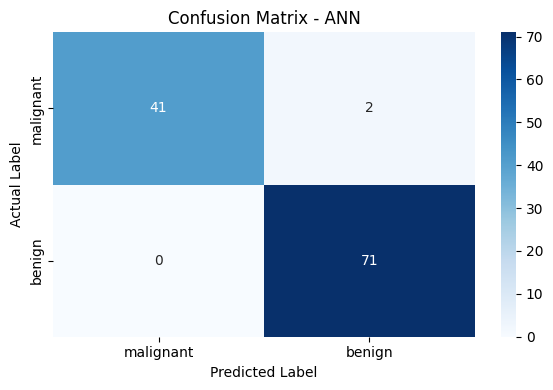

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("First five rows:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum().sum())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    verbose=1
)

y_prob = model.predict(X_test)
y_pred = (y_prob > 0.5).astype(int).ravel()

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=data.target_names
))

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - ANN')
plt.tight_layout()
plt.show()


In [2]:
import numpy as np



np.set_printoptions(precision=4, suppress=True)



# XOR input and target output

X = np.array([[0, 0],

              [0, 1],

              [1, 0],

              [1, 1]], dtype=float)

Y = np.array([[0], [1], [1], [0]], dtype=float)



np.random.seed(42)

W1 = np.random.rand(2, 2)

b1 = np.zeros((1, 2))

W2 = np.random.rand(2, 1)

b2 = np.zeros((1, 1))



def sigmoid(x):

    return 1 / (1 + np.exp(-x))



def sigmoid_derivative(a):

    return a * (1 - a)



learning_rate = 0.1

epochs = 10000



for epoch in range(1, epochs + 1):

    # FORWARD PASS

    Z1 = X @ W1 + b1

    A1 = sigmoid(Z1)

    Z2 = A1 @ W2 + b2

    A2 = sigmoid(Z2)



    # Mean squared error (before updating weights)

    error = Y - A2

    mse = np.mean(error ** 2)



    # BACKWARD PASS

    d_output = error * sigmoid_derivative(A2)

    d_hidden = (d_output @ W2.T) * sigmoid_derivative(A1)



    # Save old weights if you want to compare them

    old_W1 = W1.copy()

    old_W2 = W2.copy()



    # UPDATE WEIGHTS AND BIASES

    W2 += learning_rate * (A1.T @ d_output) / len(X)

    b2 += learning_rate * np.mean(d_output, axis=0, keepdims=True)

    W1 += learning_rate * (X.T @ d_hidden) / len(X)

    b1 += learning_rate * np.mean(d_hidden, axis=0, keepdims=True)



    # Print first few epochs and then final epoch

    if epoch <= 3 or epoch == epochs:

        print(f"\nEPOCH {epoch}")

        print("-" * 55)

        print("Forward pass - hidden output (A1):")

        print(A1)

        print("Predicted output (A2):")

        print(A2)

        print("Target output (Y):")

        print(Y)

        print("Error (Y - A2):")

        print(error)

        print(f"Mean squared error: {mse:.6f}")

        print("Backward pass - output delta:")

        print(d_output)

        print("Backward pass - hidden delta:")

        print(d_hidden)

        print("New W1:")

        print(W1)

        print("New b1:")

        print(b1)

        print("New W2:")

        print(W2)

        print("New b2:")

        print(b2)



print("\nFINAL PREDICTIONS")

print("Input       Target      Prediction")

for x, y, pred in zip(X, Y, A2):

    print(f"{x}    {y[0]:.0f}          {pred[0]:.4f}")


EPOCH 1
-------------------------------------------------------
Forward pass - hidden output (A1):
[[0.5    0.5   ]
 [0.6752 0.6453]
 [0.5926 0.7213]
 [0.7515 0.8248]]
Predicted output (A2):
[[0.5389]
 [0.5513]
 [0.5511]
 [0.5612]]
Target output (Y):
[[0.]
 [1.]
 [1.]
 [0.]]
Error (Y - A2):
[[-0.5389]
 [ 0.4487]
 [ 0.4489]
 [-0.5612]]
Mean squared error: 0.252051
Backward pass - output delta:
[[-0.1339]
 [ 0.111 ]
 [ 0.1111]
 [-0.1382]]
Backward pass - hidden delta:
[[-0.0052 -0.0052]
 [ 0.0038  0.004 ]
 [ 0.0042  0.0035]
 [-0.004  -0.0031]]
New W1:
[[0.3745 0.9507]
 [0.732  0.5987]]
New b1:
[[-0. -0.]]
New W2:
[[0.1553]
 [0.1553]]
New b2:
[[-0.0013]]

EPOCH 2
-------------------------------------------------------
Forward pass - hidden output (A1):
[[0.5    0.5   ]
 [0.6752 0.6453]
 [0.5925 0.7213]
 [0.7515 0.8248]]
Predicted output (A2):
[[0.5384]
 [0.5508]
 [0.5505]
 [0.5606]]
Target output (Y):
[[0.]
 [1.]
 [1.]
 [0.]]
Error (Y - A2):
[[-0.5384]
 [ 0.4492]
 [ 0.4495]
 [-0.5606]]
M